# Lake Pontchartrain Model Output Validation: Water Level, Salinity, and Temperature 

Validation by year against NOAA tide stations and USGS gauges,
covering the simulation. Compares hourly model output vs observations, 
with Willmott's d, Pearson r, and RMSE.

## What this notebook does

1. Loads `FlowFM_his.nc` from the your model run.
2. For **water level**, compares at 4 stations (can be changed):
   - New Canal (NOAA 8761927)
   - Shell Beach (NOAA 8761305)
   - The Rigolets (USGS 301001089442600)
3. For **salinity**, compares at 3 stations (can be changed):
   - The Rigolets (USGS parameter 00480 direct)
   - Pearl (USGS parameter 00480 direct)
4. For **water temperature**, compares at 4 stations (can be changed):
   - New Canal (NOAA 8761927, water_temperature product)
   - Shell Beach (NOAA 8761305, water_temperature product)
   - The Rigolets (USGS 301001089442600, parameter 00010)
5. Produces figures, a stats table, and a bias hint
   telling you what `DATUM_OFFSETS_*` value would zero the mean bias.

## How validation iterates

1. First run: all offsets are set to their calibrated value, observe the bias hints.
2. For each station where the absolute bias hint is high
   (roughly ~0.05 m for water level, ~0.5 psu for salinity, ~0.5 °C for temperature),
   update the corresponding key in `DATUM_OFFSETS_WL` / `DATUM_OFFSETS_SAL` /
   `DATUM_OFFSETS_TEMP` at the top of the notebook with the hint value. 
   (THIS NEEDS TO BE REPORTED for salinity and temperature
   and the model may need to be recalibrated)

**Note on temperature and salinity offsets**: unlike water-level datum offsets (which are
true datum corrections applied in post-processing), a consistent temperature
bias usually points to an upstream problem (e.x., wrong initial temperature/salinity, wrong
heat-flux configuration, or wrong boundary temperature/salinity.)  If offsets need to be changed,
additional calibration may be required, which needs to be reported. 


## 1. Setup: paths, calibration window, datum offsets

In [ ]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
import cmocean
from scipy.signal import butter, filtfilt

# Add PROJECT_ROOT to path for src imports
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.validation_functions as val_funcs

# Model output 
HIS_PATH = Path(r"C:\Users\hydro\BCS_Paper\WL_Lake_Pontchartrain_Model_2013.dsproj")

# Validation window 
start_time = pd.Timestamp("2013-01-01 00:00")
end_time   = pd.Timestamp("2013-12-31 23:00")

# Toggle which variables to validate/calibrate in this run.
# Choose any subset of: "wl", "sal", "temp"
ACTIVE_TARGETS = {"wl"}

# Model-to-observation time offset 
# This is an artifact to handle timezone shifts. I left it in just in case.
MODEL_TIME_SHIFT_HOURS = 0

# Datum offsets (m for WL)
# These start at 0. After the first run, look at "Bias hint" in the summary
# tables and copy the values back into these dicts, then re-run.

DATUM_OFFSETS_WL = {
    "NewCanal":   0.185,
    "ShellBeach": 0.026,
    "Rigolets":   -0.087,
}

# These salinity and temperatre offsets are an artifact that were used for calibration. 
# I left them in in case calibration is needed in the future.
# (deg C for temperature, psu for salinity)
DATUM_OFFSETS_SAL = {
    "Rigolets":   0.0,
    "NewCanal":   0.0,
}

DATUM_OFFSETS_TEMP = {
    "NewCanal":   0.0,
    "ShellBeach": 0.0,
    "Rigolets":   0.0,
}

# Plot styling
COLORS  = [cmocean.cm.thermal_r(0.9), cmocean.cm.thermal_r(0.5)]   # model, obs
STYLES  = ["--", "-"]                                              # model, obs
LW      = 1.25
DPI     = 200

plt.rcParams.update({
    "font.size": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.titlesize": 8, "legend.fontsize": 8, "axes.labelsize": 9,
})

print(f"Model file : {HIS_PATH}")
print(f"Window     : {start_time:%Y-%m-%d %H:%M} -> {end_time:%Y-%m-%d %H:%M}")
print(f"Active vars: {sorted(ACTIVE_TARGETS)}")
print(f"Time shift : {MODEL_TIME_SHIFT_HOURS:+d} h (model to observation window)")

Model file : C:\Users\hydro\walker_etal\2014_model\WL_Lake_Pontchartrain_Model_2014.dsproj_data\FlowFM\output\FlowFM_his.nc
Window     : 2014-01-01 00:00 -> 2014-12-31 23:00
Active vars: ['wl']
Time shift : +0 h (model to observation window)


## 2. Load the model history file

Extracts water level, salinity, and temperature at every observation station, applies the
time shift, and isolates the model window.

In [14]:
if not HIS_PATH.exists():
    raise FileNotFoundError(f"History file not found: {HIS_PATH}")

ds = xr.open_dataset(HIS_PATH)
station_names = ds["station_name"].astype(str).to_pandas().str.strip()

print(f"Simulation time : "
      f"{pd.Timestamp(ds.time.values[0])} → {pd.Timestamp(ds.time.values[-1])}")
print(f"N stations      : {len(station_names)}")
print(f"Station names   :\n  " + "\n  ".join(station_names.values))

Simulation time : 2014-01-01 00:00:00 → 2014-12-31 23:00:00
N stations      : 19
Station names   :
  Causeway_USGS
  Rigolets_CRRT
  NorthShore_CRRT
  Maurepas_CRRT
  BCS_CRRT
  SeaBoundary
  ChefMent_USACE
  BCS_USACE
  PassManac_USACE
  Madev_USACE
  LakeFrontAP_USACE
  CRMS_1006H01
  CRMS_6299H01
  CRMS_3626H01
  CRMS_4572H01
  ShellBeach_NOAA
  Rigolets_USGS
  NewCanal_USGS
  PearlRiver_USGS


In [15]:
# Load only the model variables selected in ACTIVE_TARGETS.
wl_model = None
sal_model = None
temp_model = None

if "wl" in ACTIVE_TARGETS:
    wl_model = val_funcs.load_model_variable(
        ds, station_names, "waterlevel", MODEL_TIME_SHIFT_HOURS, start_time, end_time
    )
if "sal" in ACTIVE_TARGETS:
    sal_model = val_funcs.load_model_variable(
        ds, station_names, "salinity", MODEL_TIME_SHIFT_HOURS, start_time, end_time
    )
if "temp" in ACTIVE_TARGETS:
    temp_model = val_funcs.load_model_variable(
        ds, station_names, "temperature", MODEL_TIME_SHIFT_HOURS, start_time, end_time
    )

if wl_model is not None:
    print(f"Water level in window : {wl_model.shape[0]} timesteps")
    print(f"  value range         : {wl_model.min().min():+.3f} to {wl_model.max().max():+.3f} m")
if sal_model is not None:
    print(f"Salinity in window    : {sal_model.shape[0]} timesteps")
    print(f"  value range         : {sal_model.min().min():.2f} to {sal_model.max().max():.2f} psu")
if temp_model is not None:
    print(f"Temperature in window : {temp_model.shape[0]} timesteps")
    print(f"  value range         : {temp_model.min().min():.2f} to {temp_model.max().max():.2f} C")

Water level in window : 8760 timesteps
  value range         : -0.281 to +1.027 m


## 3. Validation
The three metrics used in the comparison
- **Willmott's d** (index of agreement, 0 to 1, higher = better)
- **Pearson r** (linear correlation, -1 to 1)
- **RMSE** (in the variable's native units)

Validates for USGS and NOAA stations. 
(Need to update for csv files, such as USACE data stations and loggers)
**Note**: Occasionally code blocks will fail because USGS times out (HTTPSConnectionPool error). Try rerunning this block. 

Each section provides statistical results, a figure, and summary (that includes offsets).

### 3.1 Water Level Validation

In [16]:
if "wl" in ACTIVE_TARGETS:
    wl_stations = [
        {"label": "New Canal (NOAA 8761927)",          
         "model_col": "NewCanal_USGS",
         "fetcher": lambda: val_funcs.fetch_noaa_wl("8761927", start_time, end_time),
         "offset_key": "NewCanal"},
        {"label": "Shell Beach (NOAA 8761305)",        
         "model_col": "ShellBeach_NOAA",
         "fetcher": lambda: val_funcs.fetch_noaa_wl("8761305", start_time, end_time),
         "offset_key": "ShellBeach"},
        {"label": "The Rigolets (USGS 301001089442600)",
         "model_col": "Rigolets_USGS",
         "fetcher": lambda: val_funcs.fetch_usgs_wl("301001089442600", start_time, end_time),
         "offset_key": "Rigolets"},
    ]

    wl_results = val_funcs.validate_variable(
        wl_stations, wl_model, start_time, end_time, DATUM_OFFSETS_WL, "wl"
    )
else:
    wl_results = []
    print("Skipping water level validation (wl not in ACTIVE_TARGETS).")


New Canal (NOAA 8761927)
  fetched obs: 87591 raw values
  d=0.97  r=0.96  RMSE=0.053  n=8760  | offset=+0.185  bias_hint=+0.160

Shell Beach (NOAA 8761305)
  fetched obs: 87591 raw values
  d=0.98  r=0.97  RMSE=0.054  n=8760  | offset=+0.026  bias_hint=+0.005

The Rigolets (USGS 301001089442600)
  fetched obs: 8146 raw values
  d=0.93  r=0.87  RMSE=0.085  n=8146  | offset=-0.087  bias_hint=-0.106


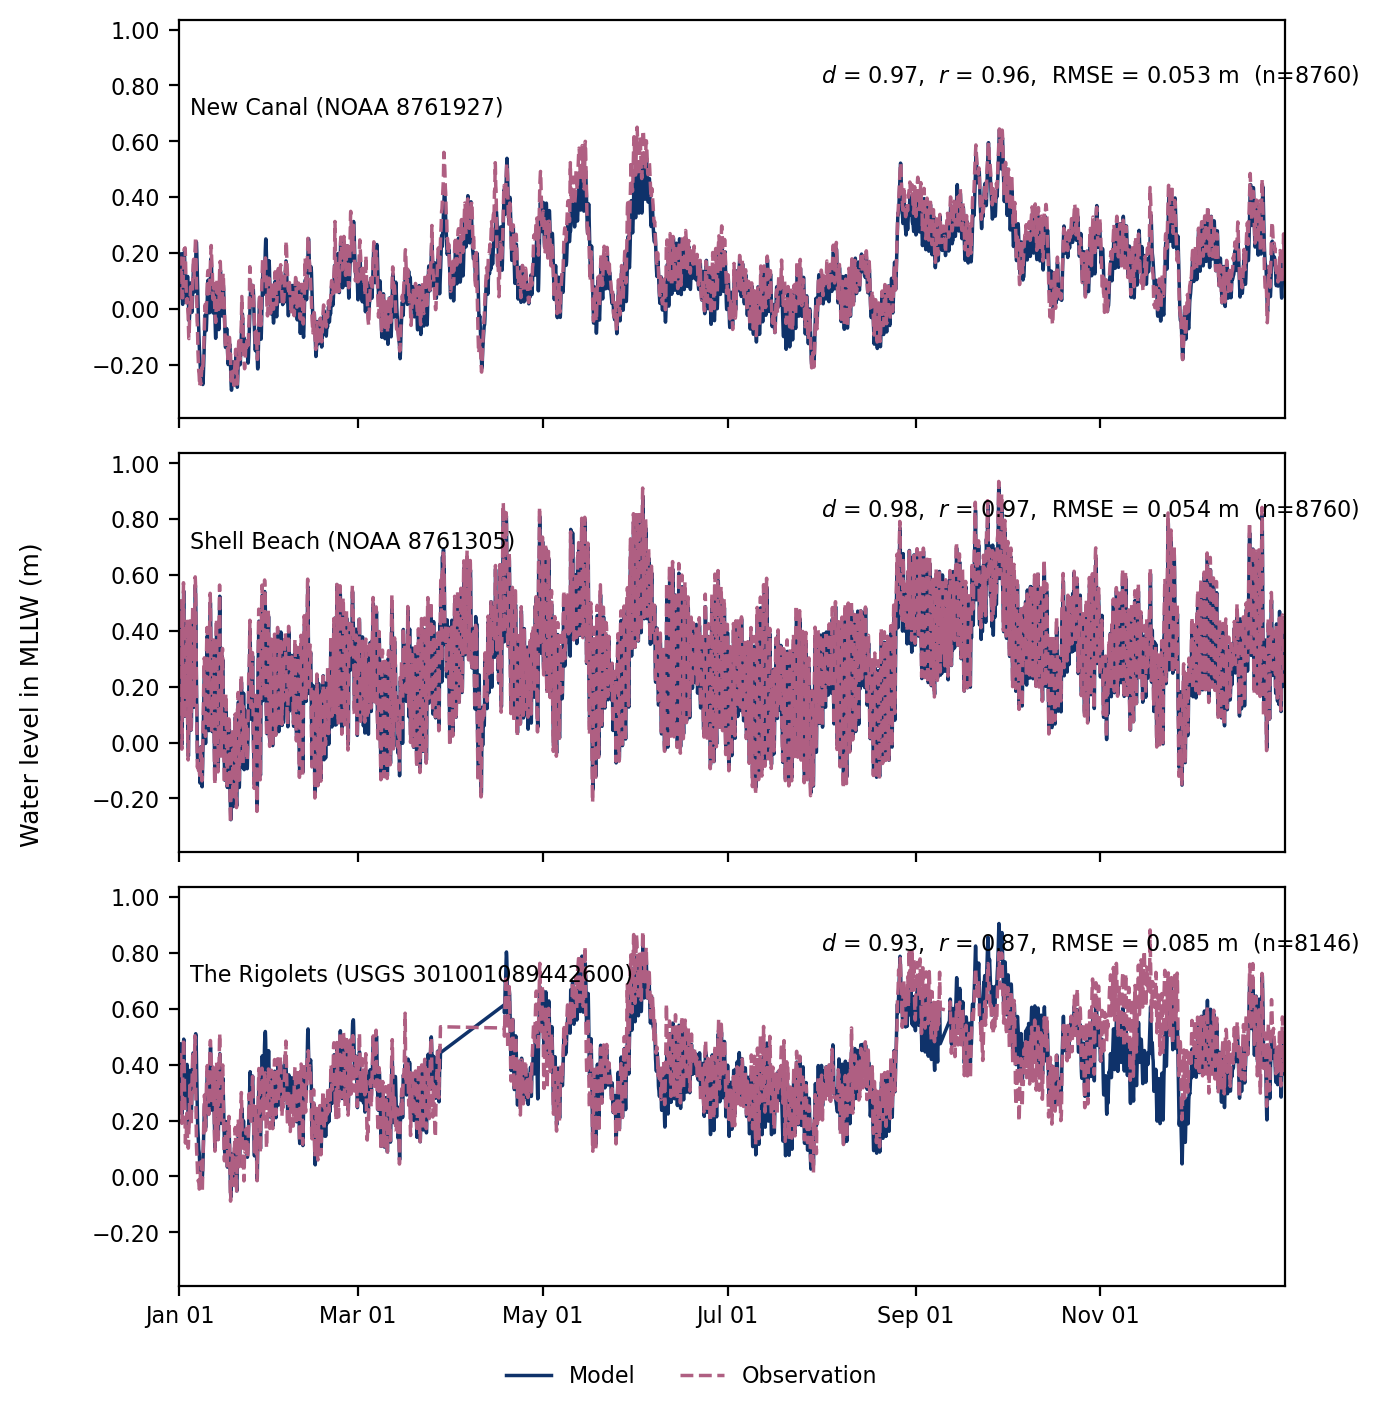

In [17]:
if not wl_results:
    print("No water level results to plot.")
else:
    fig, axs = plt.subplots(nrows=len(wl_results), ncols=1,
                            sharex=True, figsize=(7, 7), dpi=DPI)
    plt.subplots_adjust(hspace=0.30)

    # Common y-limits based on data range across all panels
    all_vals = pd.concat([r["paired"] for r in wl_results if not r["paired"].empty])
    if not all_vals.empty:
        y_lo = float(all_vals.min().min()) - 0.1
        y_hi = float(all_vals.max().max()) + 0.1
    else:
        y_lo, y_hi = -0.5, 1.5

    for i, res in enumerate(wl_results):
        ax = axs[i]
        p = res["paired"]
        if not p.empty:
            # Markers + lines so sparse data (even a single point) is visible
            ax.plot(p.index, p["model"], lw=LW, color=COLORS[0], ls=STYLES[1],
                mec="none", label="Model")
            ax.plot(p.index, p["obs"],   lw=LW, color=COLORS[1], ls=STYLES[0],
                 mec="none", label="Obs")
        ax.set_xlim(start_time, end_time)
        ax.set_ylim(y_lo, y_hi)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.2f}"))
        ax.set_title(res["label"], loc="left", x=0.01, y=0.72, fontsize=8)
        if np.isfinite(res["d"]):
            ax.text(0.58, 0.86,
                    f"$d$ = {res['d']:.2f},  $r$ = {res['r']:.2f},  "
                    f"RMSE = {res['rmse']:.3f} m  (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center")
        else:
            ax.text(0.58, 0.86,
                    f"stats unavailable (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center",
                    color="firebrick")

    axs[-1].xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    fig.supylabel("Water level in MLLW (m)", fontsize=9)
    fig.legend(["Model", "Observation"], loc="lower center", ncol=2,
               frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=[0.02, 0.03, 1, 1])
    plt.show()

In [18]:
if not wl_results:
    print("No water level summary to report.")
else:
    wl_summary = pd.DataFrame([{
        "Station":              r["label"],
        "n_pairs":              r["n"],
        "d":                    round(r["d"], 3)         if np.isfinite(r["d"])    else np.nan,
        "r":                    round(r["r"], 3)         if np.isfinite(r["r"])    else np.nan,
        "RMSE (m)":             round(r["rmse"], 3)      if np.isfinite(r["rmse"]) else np.nan,
        "Applied offset (m)":   round(r["applied_offset"], 3),
        "Bias hint (m)":        round(r["bias_hint"], 3) if np.isfinite(r["bias_hint"]) else np.nan,
    } for r in wl_results])
    print(wl_summary.to_string(index=False))

                            Station  n_pairs     d     r  RMSE (m)  Applied offset (m)  Bias hint (m)
           New Canal (NOAA 8761927)     8760 0.971 0.959     0.053               0.185          0.160
         Shell Beach (NOAA 8761305)     8760 0.981 0.969     0.054               0.026          0.005
The Rigolets (USGS 301001089442600)     8146 0.929 0.874     0.085              -0.087         -0.106


## 3.2 Salinity Validation

In [19]:
if "sal" in ACTIVE_TARGETS:
    sal_stations = [
        {"label": "The Rigolets (USGS 301001089442600)","model_col": "Rigolets_CRRT",
         "fetcher": lambda: val_funcs.fetch_usgs_salinity_direct("301001089442600", start_time, end_time),
         "offset_key": "Rigolets"},
         {"label": "The Rigolets (USGS 301001089442600)","model_col": "Rigolets_CRRT",
         "fetcher": lambda: val_funcs.fetch_usgs_salinity_direct("301001089442600", start_time, end_time),
         "offset_key": "Rigolets"}
    ]

    sal_results = val_funcs.validate_variable(
        sal_stations, sal_model, start_time, end_time, DATUM_OFFSETS_SAL, "sal"
    )
else:
    sal_results = []
    print("Skipping salinity validation (sal not in ACTIVE_TARGETS).")

Skipping salinity validation (sal not in ACTIVE_TARGETS).


In [20]:
if not sal_results:
    print("No salinity results to plot.")
else:
    fig, axs = plt.subplots(nrows=len(sal_results), ncols=1,
                            sharex=True, figsize=(7, 5.5), dpi=DPI)
    plt.subplots_adjust(hspace=0.30)

    all_vals = pd.concat([r["paired"] for r in sal_results if not r["paired"].empty])
    if not all_vals.empty:
        y_lo = max(0.0, float(all_vals.min().min()) - 0.5)
        y_hi = float(all_vals.max().max()) + 1.0
    else:
        y_lo, y_hi = 0.0, 20.0

    for i, res in enumerate(sal_results):
        ax = axs[i]
        p = res["paired"]
        if not p.empty:
            ax.plot(p.index, p["model"], lw=LW, color=COLORS[0], ls=STYLES[1],
                    mec="none", label="Model")
            ax.plot(p.index, p["obs"],   lw=LW, color=COLORS[1], ls=STYLES[0],
                    mec="none", label="Obs")
        ax.set_xlim(start_time, end_time)
        ax.set_ylim(y_lo, y_hi)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.1f}"))
        ax.set_title(res["label"], loc="left", x=0.01, y=0.72, fontsize=8)
        if np.isfinite(res["d"]):
            ax.text(0.58, 0.86,
                    f"$d$ = {res['d']:.2f},  $r$ = {res['r']:.2f},  "
                    f"RMSE = {res['rmse']:.2f} psu  (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center")
        else:
            ax.text(0.58, 0.86,
                    f"stats unavailable (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center",
                    color="firebrick")

    axs[-1].xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    fig.supylabel("Salinity (psu)", fontsize=9)
    fig.legend(["Model", "Observation"], loc="lower center", ncol=2,
               frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=[0.02, 0.03, 1, 1])
    plt.show()

No salinity results to plot.


In [21]:
if not sal_results:
    print("No salinity summary to report.")
else:
    sal_summary = pd.DataFrame([{
        "Station":                 r["label"],
        "n_pairs":                 r["n"],
        "d":                       round(r["d"], 3)         if np.isfinite(r["d"])    else np.nan,
        "r":                       round(r["r"], 3)         if np.isfinite(r["r"])    else np.nan,
        "RMSE (psu)":              round(r["rmse"], 3)      if np.isfinite(r["rmse"]) else np.nan,
        "Applied offset (psu)":    round(r["applied_offset"], 3),
        "Bias hint (psu)":         round(r["bias_hint"], 3) if np.isfinite(r["bias_hint"]) else np.nan,
    } for r in sal_results])
    print(sal_summary.to_string(index=False))

No salinity summary to report.


## 3.3 Temperature Validation

In [22]:
if "temp" in ACTIVE_TARGETS:
    temp_stations = [
        {"label": "New Canal (NOAA 8761927)", 
         "model_col": "NewCanal_USGS",
         "fetcher": lambda: val_funcs.fetch_noaa_water_temp("8761927", start_time, end_time),
         "offset_key": "NewCanal"},
        {"label": "Shell Beach (NOAA 8761305)", 
         "model_col": "ShellBeach_NOAA",
         "fetcher": lambda: val_funcs.fetch_noaa_water_temp("8761305", start_time, end_time),
         "offset_key": "ShellBeach"},
        {"label": "The Rigolets (USGS 301001089442600)",
         "model_col": "Rigolets_CRRT",
         "fetcher": lambda: val_funcs.fetch_usgs_water_temp("301001089442600", start_time, end_time),
         "offset_key": "Rigolets"},
    ]

    temp_results = val_funcs.validate_variable(
        temp_stations, temp_model, start_time, end_time, DATUM_OFFSETS_TEMP, "temp"
    )
else:
    temp_results = []
    print("Skipping temperature validation (temp not in ACTIVE_TARGETS).")

Skipping temperature validation (temp not in ACTIVE_TARGETS).


### 7.1 Temperature figure

In [23]:
if not temp_results:
    print("No temperature results to plot.")
else:
    fig, axs = plt.subplots(nrows=len(temp_results), ncols=1,
                            sharex=True, figsize=(7, 7), dpi=DPI)
    plt.subplots_adjust(hspace=0.30)

    all_vals = pd.concat([r["paired"] for r in temp_results if not r["paired"].empty])
    if not all_vals.empty:
        y_lo = float(all_vals.min().min()) - 1.0
        y_hi = float(all_vals.max().max()) + 1.0
    else:
        y_lo, y_hi = 0.0, 30.0

    for i, res in enumerate(temp_results):
        ax = axs[i]
        p = res["paired"]
        if not p.empty:
            ax.plot(p.index, p["model"], lw=LW, color=COLORS[0], ls=STYLES[1],
                   mec="none", label="Model")
            ax.plot(p.index, p["obs"],   lw=LW, color=COLORS[1], ls=STYLES[0],
                    mec="none", label="Obs")
        ax.set_xlim(start_time, end_time)
        ax.set_ylim(y_lo, y_hi)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.1f}"))
        ax.set_title(res["label"], loc="left", x=0.01, y=0.72, fontsize=8)
        if np.isfinite(res["d"]):
            ax.text(0.58, 0.86,
                    f"$d$ = {res['d']:.2f},  $r$ = {res['r']:.2f},  "
                    f"RMSE = {res['rmse']:.2f} C  (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center")
        else:
            ax.text(0.58, 0.86,
                    f"stats unavailable (n={res['n']})",
                    transform=ax.transAxes, fontsize=8, va="center",
                    color="firebrick")

    axs[-1].xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    fig.supylabel("Water temperature (C)", fontsize=9)
    fig.legend(["Model", "Observation"], loc="lower center", ncol=2,
               frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=[0.02, 0.03, 1, 1])
    plt.show()

No temperature results to plot.


In [24]:
if not temp_results:
    print("No temperature summary to report.")
else:
    temp_summary = pd.DataFrame([{
        "Station":                 r["label"],
        "n_pairs":                 r["n"],
        "d":                       round(r["d"], 3)         if np.isfinite(r["d"])    else np.nan,
        "r":                       round(r["r"], 3)         if np.isfinite(r["r"])    else np.nan,
        "RMSE (C)":                round(r["rmse"], 3)      if np.isfinite(r["rmse"]) else np.nan,
        "Applied offset (C)":      round(r["applied_offset"], 3),
        "Bias hint (C)":           round(r["bias_hint"], 3) if np.isfinite(r["bias_hint"]) else np.nan,
    } for r in temp_results])
    print(temp_summary.to_string(index=False))
    print()
    print("Unlike water-level offsets, a temperature bias usually means the")
    print("heat-flux forcing or boundary temperature is off. Treat the bias hint as")
    print("a diagnostic: if the bias is consistent across all 4 stations, the problem")
    print("is atmospheric forcing (FlowFM_meteo.tim) or boundary conditions, not a")
    print("station-specific correction. If it's big at one station only, check that")
    print("station's local forcing (e.g., river discharge temperature).")

No temperature summary to report.
